## Accessing Animal Tracking - Satellite Relay Tagging - Delayed Mode - Summary (Parquet)
This Jupyter notebook demonstrates how to access and plot animal_summary_satellite_relay_tagging_location_qc_delayed_qc data, available as a [Parquet](https://parquet.apache.org) dataset stored on S3.

🔗 More information about the dataset is available [in the AODN metadata catalogue](https://catalogue-imos.aodn.org.au/geonetwork/srv/eng/catalog.search#/metadata/70f148b1-7040-4fad-944a-456413c95472).

📌 The source of truth for this notebook is maintained on [GitHub](https://github.com/aodn/aodn_cloud_optimised/tree/main/notebooks/animal_summary_satellite_relay_tagging_location_qc_delayed_qc.ipynb).


In [1]:
dataset_name = "animal_summary_satellite_relay_tagging_location_qc_delayed_qc"

## Install/Update packages and Load common functions

In [2]:
import os, requests, importlib.util

open('setup.py', 'w').write(requests.get('https://raw.githubusercontent.com/aodn/aodn_cloud_optimised/main/notebooks/setup.py').text)

spec = importlib.util.spec_from_file_location("setup", "setup.py")
setup = importlib.util.module_from_spec(spec)
spec.loader.exec_module(setup)

setup.install_requirements()
setup.load_dataquery()

✅ Virtual environment already exists, skipping creation.


Using Python 3.12.11 environment at: /home/ecougnon/anaconda3/envs/AodnCloudOptimised
Resolved 201 packages in 70ms
Audited 201 packages in 0.06ms


✅ Local version 0.3.30 is up to date (remote: 0.3.30)


In [ ]:
from DataQuery import GetAodn

# Understanding the Dataset

## Understanding Parquet Partitioning

Parquet files can be **partitioned** by one or more columns, which means the data is physically organised into folders based on the values in those columns. This is similar to how databases use indexes to optimise query performance.

Partitioning enables **faster filtering**: when you query data using a partitioned column, only the relevant subset of files needs to be read—improving performance significantly.

For example, if a dataset is partitioned by `"site_code"`, `"timestamp"`, and `"polygon"`, filtering on `"site_code"` allows the system to skip unrelated files entirely.

In this notebook, the `GetAodn` class includes built-in methods to efficiently filter data by **time** and **latitude/longitude** using the **timestamp** and **polygon** partitions. Other partitions can be used for filtering via the `scalar_filter`.

Any filtering on columns that are **not** partitioned can be significantly slower, as all files may need to be scanned. However, the `GetAodn` class provides a `scalar_filter` method that lets you apply these filters at load time—before the data is fully read—helping reduce the size of the resulting DataFrame.

Once the dataset is loaded, further filtering using Pandas is efficient and flexible.

See further below in the notebook for examples of how to filter the data effectively.

To view the actual partition columns for this dataset, run:


In [4]:
aodn = GetAodn()
dname = f'{dataset_name}.parquet'
%time aodn_dataset = aodn.get_dataset(dname)

CPU times: user 7.32 ms, sys: 89 µs, total: 7.41 ms
Wall time: 6.54 ms


In [5]:
aodn_dataset.dataset.partitioning.schema

timestamp: int32
polygon: string

## List unique partition values

In [6]:
%%time
unique_partition_value = aodn_dataset.get_unique_partition_values('YOUR_PARTITION_KEY')
print(list(unique_partition_value)[0:2])  # showing a subset only

[]
CPU times: user 639 µs, sys: 0 ns, total: 639 µs
Wall time: 550 µs


## Visualise Spatial Extent of the dataset
This section plots the polygons representing the areas where data is available. It helps to identify and create a bounding box around the regions containing data.

/home/ecougnon/anaconda3/envs/AodnCloudOptimised/lib/python3.12/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


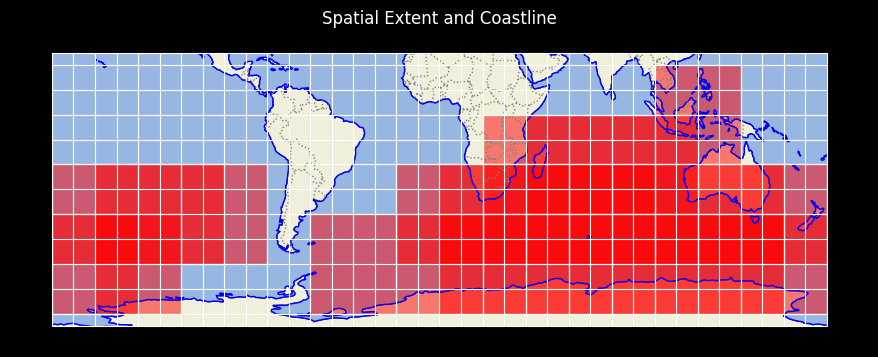

In [6]:
aodn_dataset.plot_spatial_extent()

## Get Temporal Extent of the dataset

Similary to the spatial extent, we're retrieving the minimum and maximum timestamp partition values of the dataset. This is not necessarely accurately representative of the TIME values, as the timestamp partition can be yearly/monthly... but is here to give an idea

In [7]:
%%time
aodn_dataset.get_temporal_extent()

CPU times: user 217 ms, sys: 36.8 ms, total: 254 ms
Wall time: 678 ms


(Timestamp('2018-10-14 12:00:00'), Timestamp('2025-12-06 12:00:00'))

## Read Metadata

For all Parquet datasets, we create a sidecar file named **_common_metadata** in the root of the dataset. This file contains both the dataset-level and variable-level attributes.  
The metadata can be retrieved below as a dictionary, and it will also be included in the pandas DataFrame when using the `get_data` method from the `GetAodn` class.

In [8]:
metadata = aodn_dataset.get_metadata()
metadata

2026-10-14 09:35:31,461 - aodn.GetAodn - INFO - Retrieving metadata for imos-optimised-nonproduction/animal_summary_satellite_relay_tagging_location_qc_delayed_qc.parquet


{'cid': {'type': 'string', 'comment': 'SMRU campaign name '},
 'cnt': {'type': 'int32',
  'comment': 'The number of times that this record was received'},
 'pca': {'type': 'double'},
 'ptt': {'type': 'int32',
  'comment': 'Argos PTT number is used',
  'long_name': 'Platform Transmitter Terminal'},
 'ref': {'type': 'string',
  'comment': 'A three-part code (e.g. rs3-Fred-07) : The first part identifies the batch of tags, the second part is the name or number of the animal, the third part is the year',
  'long_name': 'reference'},
 'ssm_x': {'type': 'double',
  'units': 'km',
  'comment': 'projection for ssm_x,ssm_y coordinates is given in the metadata: `qc_proj4string`',
  'long_name': 'State-space model-estimated X coordinate (E-W)'},
 'ssm_y': {'type': 'double',
  'units': 'km',
  'comment': 'projection for ssm_x,ssm_y coordinates is given in the metadata: `qc_proj4string`',
  'long_name': 'State-space model-estimated Y coordinate (N-S)'},
 'av_dur': {'type': 'int32',
  'units': 's',


# Data Query and Plot

## Create a TIME and BoundingBox filter

This cell loads a subset of the dataset based on a time range and a spatial bounding box. The result is returned as a pandas DataFrame, and basic information about its structure is displayed.

In [9]:
%%time
df = aodn_dataset.get_data(date_start='2019-12-01',
                           date_end='2020-10-15')


df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41806 entries, 0 to 41805
Data columns (total 61 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   cid              41806 non-null  object        
 1   cnt              41806 non-null  int32         
 2   pca              2781 non-null   float64       
 3   ptt              41806 non-null  int32         
 4   ref              41806 non-null  object        
 5   ssm_x            41806 non-null  float64       
 6   ssm_y            41806 non-null  float64       
 7   av_dur           41806 non-null  int32         
 8   e_date           41806 non-null  datetime64[ns]
 9   s_date           41806 non-null  datetime64[ns]
 10  sd_dur           38618 non-null  float64       
 11  avg_sst          0 non-null      float64       
 12  dive_tm          41806 non-null  float64       
 13  haul_tm          41806 non-null  float64       
 14  max_dur          41806 non-null  int32

In [10]:
df

,cid,cnt,pca,ptt,ref,ssm_x,ssm_y,av_dur,e_date,s_date,...,swim_eff_desc,av_haulout_dur,dp_av_surf_dur,dp_sd_surf_dur,sd_haulout_dur,swim_eff_whole,dp_max_surf_dur,max_haulout_dur,timestamp,polygon
0,ct157,32,NaN,197017,ct157-C208-20,-2288.756655,3994.842942,0,2019-12-26 06:00:00,2019-12-26 00:00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1546300800,0103000000010000000500000000000000000044400000...
1,ct157,32,NaN,197017,ct157-C208-20,-2288.301628,3994.954869,0,2019-12-26 12:00:00,2019-12-26 06:00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1546300800,0103000000010000000500000000000000000044400000...
2,ct157,9,NaN,197017,ct157-C208-20,-2290.359182,3994.640557,16,2019-12-26 18:00:00,2019-12-26 12:00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1546300800,0103000000010000000500000000000000000044400000...
3,ct157,9,NaN,197017,ct157-C208-20,-2294.252008,3992.311974,176,2019-12-27 00:00:00,2019-12-26 18:00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1546300800,0103000000010000000500000000000000000044400000...
4,ct157,9,NaN,197017,ct157-C208-20,-2294.612931,3989.617909,0,2019-12-27 06:00:00,2019-12-27 00:00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1546300800,0103000000010000000500000000000000000044400000...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41801,ct156,6,NaN,158102,ct156-R881BAT-09,132.474835,1321.575137,1230,2020-10-15 06:00:00,2020-10-15 00:00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1577836800,0103000000010000000500000000000000008061400000...
41802,ct157,1163,NaN,196990,ct157-C182-20,-2840.762234,2759.264002,1320,2020-10-15 06:00:00,2020-10-15 00:00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1577836800,0103000000010000000500000000000000000034400000...
41803,ct157,2261,NaN,197024,ct157-C201-20,1371.531714,3146.816154,1192,2020-10-15 06:00:00,2020-10-15 00:00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1577836800,0103000000010000000500000000000000000059400000...
41804,ct157,201,NaN,197012,ct157-C211-20,-35.956131,2839.124247,0,2020-10-15 06:00:00,2020-10-15 00:00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1577836800,010300000001000000050000000000000000004E400000...


In [12]:
## Download Subsetted Data as CSV

# This cell downloads the filtered dataset as a ZIP-compressed CSV file.  
# The CSV includes metadata at the top as commented lines, and a `FileLink` object is returned to allow downloading directly from the notebook.


#df.aodn.download_as_csv()

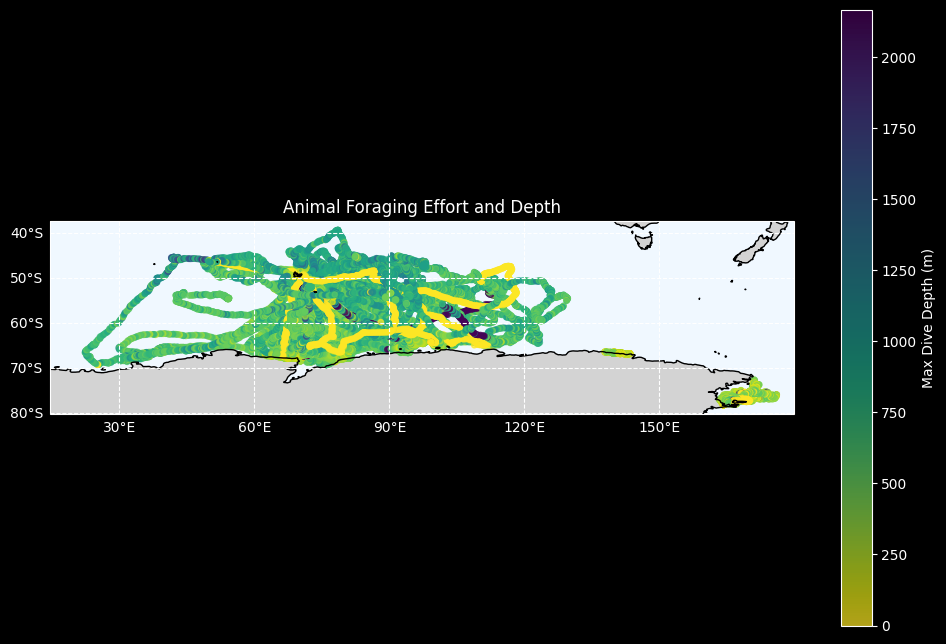

In [11]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Set up the figure with a PlateCarree projection (standard lat/lon)
fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

# Add land, ocean, and coastlines
ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax.add_feature(cfeature.COASTLINE, linewidth=1)

# Plot your behavioral data
# Using 'max_depth' as a proxy for foraging effort
sc = ax.scatter(df['ssm_lon'], df['ssm_lat'], c=df['max_depth'], 
                cmap='viridis_r', s=15, alpha=0.7, 
                transform=ccrs.PlateCarree(), label='Dive Location')

plt.colorbar(sc, label='Max Dive Depth (m)')
plt.title('Animal Foraging Effort and Depth')

# Add gridlines with labels
gl = ax.gridlines(draw_labels=True, linestyle='--')
gl.top_labels = False
gl.right_labels = False

plt.show()